# Phase 2B · 01 · Tuned random forest

**Goal:** keep the paper's data, normalization and evaluation exactly as in Phase 2A, but let the random forest choose its own settings instead of using fixed ones. Then compare its AUC with the 2A forest (0.808) and the paper (0.84).

1. What tuning is, and the settings we search.
2. Nested cross-validation: tuning without ever seeing the test studies.
3. Unified evaluation, study-blocked 10×10 CV with the median.
4. Leave-one-study-out (LOSO).
5. Which settings won.
6. Experiment log (MLflow).

## Setup

Inputs come from notebook 1/03 (the 347 genera and the labels) and from the 2A tables (2A and paper AUCs for comparison). Outputs go to `results/figures/phase_2/phase_2b/01_tuned_random_forest/` and `results/tables/phase_2/phase_2b/01_tuned_random_forest/`.

`QUICK = True` runs 1 repeat instead of 10 and tries 4 settings instead of 10. It is only for checking that everything works, so it writes no tables and no MLflow record. The reported results come from `QUICK = False`, the paper's full 10×10 evaluation.

In [13]:
import os
import subprocess
import time
from pathlib import Path

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.pipeline import Pipeline

QUICK = False
SEED = 2000
N_REPEATS = 1 if QUICK else 10
N_ITER = 4 if QUICK else 10
print(f"QUICK = {QUICK}: {N_REPEATS} repeat(s) of 10 folds, {N_ITER} settings tried per split")


def find_project_root() -> Path:
    """Walk up from the current folder to the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("No requirements.txt above this folder.")
        folder = folder.parent
    return folder


PROJECT_ROOT = find_project_root()
INPUTS = PROJECT_ROOT / "data" / "processed" / "phase_1" / "03_preprocessing"
TABLES_2A = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2a"
FIGURES = PROJECT_ROOT / "results" / "figures" / "phase_2" / "phase_2b" / "01_tuned_random_forest"
TABLES = PROJECT_ROOT / "results" / "tables" / "phase_2" / "phase_2b" / "01_tuned_random_forest"
for folder in (FIGURES, TABLES):
    folder.mkdir(parents=True, exist_ok=True)

figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    fig.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))


PSEUDOCOUNT = 1e-5


def fit_log_std(relab: pd.DataFrame) -> tuple[pd.Series, pd.Series]:
    """Learn each genus's mean and spread (standard deviation + its 10th percentile) on the log scale."""
    logged = np.log10(relab + PSEUDOCOUNT)
    sd = logged.std(ddof=1)
    floor = np.quantile(sd, 0.1)
    assert floor > 0, "the 10th percentile of the SDs must be above 0"
    return logged.mean(), sd + floor


def apply_log_std(relab: pd.DataFrame, mean: pd.Series, spread: pd.Series) -> pd.DataFrame:
    """Log-transform and standardize with already learned numbers."""
    return (np.log10(relab + PSEUDOCOUNT) - mean) / spread

QUICK = False: 10 repeat(s) of 10 folds, 10 settings tried per split


In [14]:
relab = pd.read_csv(INPUTS / "relab_347.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
labels = pd.read_csv(INPUTS / "labels.csv", index_col="Sample_ID", dtype={"Sample_ID": str})
assert relab.index.equals(labels.index), "features and labels must be in the same row order"

y = labels["label"].to_numpy()
groups = labels["Cohort"].to_numpy()
studies = sorted(set(groups))

unified_2a = pd.read_csv(TABLES_2A / "01_unified_random_forest" / "unified_auc.csv")
loso_2a = pd.read_csv(TABLES_2A / "02_loso_random_forest" / "loso_auc.csv", index_col="study")
AUC_2A = unified_2a["auc"].iloc[0]
AUC_PAPER = unified_2a["paper_auc"].iloc[0]
print(f"{relab.shape[0]:,} samples, {relab.shape[1]} genera, {len(studies)} studies. 2A AUC {AUC_2A:.3f}, paper {AUC_PAPER}")

5,966 samples, 347 genera, 27 studies. 2A AUC 0.808, paper 0.84


## 1. What tuning is

A model's **hyperparameters** are the settings we choose before training, as opposed to what the model learns from the data. In 2A the forest used fixed settings: 200 trees and √347 ≈ 18 candidate features per split. Nobody showed that those are the best for this data. **Tuning** tries several settings and keeps the one that scores best.

The four settings we search, and what each one changes:

- `n_estimators`: how many trees vote. More trees give a steadier vote but take longer.
- `max_features`: how many genera a tree may choose from at each split. Fewer makes the trees more different from each other.
- `min_samples_leaf`: the smallest group of samples a tree may end in. Larger values stop trees from memorizing single samples.
- `max_depth`: how many questions deep a tree may grow. `None` means no limit, as in 2A.

All combinations would be 3 × 4 × 4 × 3 = 144 forests per split, too many. **Randomized search** picks a fixed number of combinations at random and tries only those. The same random seed is used every time, so every split compares the same candidates. These ranges are our choice. The paper does not tune.

In [15]:
SPACE = {
    "model__n_estimators": [200, 500, 1000],
    "model__max_features": ["sqrt", "log2", 0.1, 0.2],
    "model__min_samples_leaf": [1, 2, 5, 10],
    "model__max_depth": [None, 10, 20],
}
n_combinations = int(np.prod([len(values) for values in SPACE.values()]))
print(f"{n_combinations} combinations in the space, {N_ITER} tried per split")

144 combinations in the space, 10 tried per split


## 2. Nested cross-validation

If we picked the best settings by their score on the test folds, the test folds would have helped choose the model, and the final score would be too optimistic. So tuning happens in a second, inner loop that sees only the training studies:

- **Outer loop** (as in 2A): split the 27 studies into 10 folds. Train on 9, test on 1.
- **Inner loop**: inside the 9 training folds only, split their studies again into 3 parts, grouped by study. Score each candidate setting by its average AUC on those 3 parts. The best one is then trained on all 9 training folds and tested once on the outer test fold.

The test studies never reach the inner loop. The normalization from 2A is wrapped as a pipeline step (`LogStd`), so inside the inner loop it is also learned only on the inner training part.

In [16]:
class LogStd(BaseEstimator, TransformerMixin):
    """The 2A normalization as a pipeline step: learn on fit, apply the frozen numbers on transform."""

    def fit(self, X: pd.DataFrame, y: np.ndarray | None = None) -> "LogStd":
        self.mean_, self.spread_ = fit_log_std(X)
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        normalized = apply_log_std(X, self.mean_, self.spread_)
        assert np.isfinite(normalized.to_numpy()).all(), "no NaN or inf after normalizing"
        return normalized


pipeline = Pipeline([("log_std", LogStd()), ("model", RandomForestClassifier(n_jobs=1, random_state=SEED))])


def tune_and_predict(train_idx: np.ndarray, test_idx: np.ndarray) -> tuple[np.ndarray, dict, float]:
    """Choose settings with an inner study-blocked CV on the training rows, refit them, and score the test rows."""
    search = RandomizedSearchCV(
        pipeline, SPACE, n_iter=N_ITER, scoring="roc_auc", cv=StratifiedGroupKFold(n_splits=3),
        n_jobs=-1, random_state=SEED, refit=False,
    )
    search.fit(relab.iloc[train_idx], y[train_idx], groups=groups[train_idx])
    best = clone(pipeline).set_params(**search.best_params_, model__n_jobs=-1)
    best.fit(relab.iloc[train_idx], y[train_idx])
    return best.predict_proba(relab.iloc[test_idx])[:, 1], search.best_params_, search.best_score_

## 3. Unified evaluation

The same outer folds as in 2A (same splitter, same seeds), so the only difference from 2A is the tuning. Each sample gets one prediction per repeat, and the repeats are combined with the median, as the paper's Methods state.

In [5]:
folds = []
for repeat in range(N_REPEATS):
    splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED + repeat)
    folds.append(list(splitter.split(np.zeros(len(y)), y, groups)))

start = time.perf_counter()
predictions = np.full((len(y), N_REPEATS), np.nan)
chosen_rows = []
for repeat, repeat_folds in enumerate(folds):
    for fold, (train_idx, test_idx) in enumerate(repeat_folds):
        predictions[test_idx, repeat], best_params, inner_auc = tune_and_predict(train_idx, test_idx)
        chosen_rows.append({"split": f"repeat{repeat}_fold{fold}", "inner_auc": inner_auc, **best_params})
print(f"Tuned {len(chosen_rows)} outer splits ({len(chosen_rows) * N_ITER * 3:,} inner forests) in {time.perf_counter() - start:.0f} s")

Tuned 100 outer splits (3,000 inner forests) in 10736 s


In [6]:
median_prediction = np.median(predictions, axis=1)
auc = roc_auc_score(y, median_prediction)
auc_per_repeat = [roc_auc_score(y, predictions[:, repeat]) for repeat in range(N_REPEATS)]

unified = pd.DataFrame([{
    "model": "tuned random forest", "auc_median": round(auc, 4),
    "auc_repeat_min": round(min(auc_per_repeat), 4), "auc_repeat_max": round(max(auc_per_repeat), 4),
    "auc_2a": AUC_2A, "auc_paper": AUC_PAPER,
}])
if not QUICK:
    unified.to_csv(TABLES / "unified_auc.csv", index=False)
print(f"AUC (median over repeats): {auc:.3f}   2A: {AUC_2A:.3f}   paper: {AUC_PAPER}")
print(f"AUC of the single repeats: {min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}")

AUC (median over repeats): 0.808   2A: 0.808   paper: 0.84
AUC of the single repeats: 0.803 to 0.809


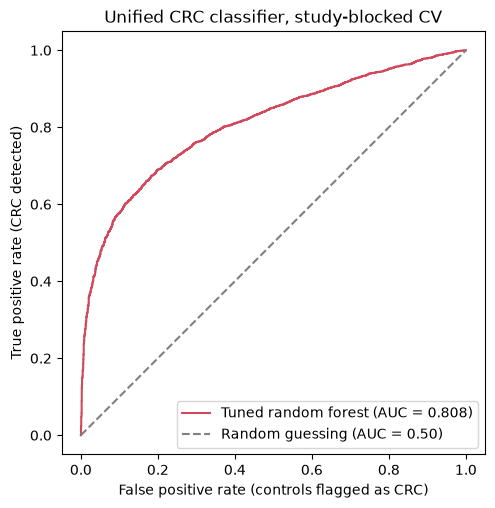

**Figure 1.** ROC curve of the tuned forest's median predictions for 5,966 samples. AUC = 0.808, against 0.808 for the 2A forest (-0.001) and 0.84 in the paper (-0.032). The single repeats range from 0.803 to 0.809. At a 10% false positive rate the model detects 58% of CRC samples.

In [7]:
false_positive_rate, true_positive_rate, _ = roc_curve(y, median_prediction)

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(false_positive_rate, true_positive_rate, color="#D1495B", label=f"Tuned random forest (AUC = {auc:.3f})")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing (AUC = 0.50)")
ax.set_xlabel("False positive rate (controls flagged as CRC)")
ax.set_ylabel("True positive rate (CRC detected)")
ax.set_title("Unified CRC classifier, study-blocked CV")
ax.legend(loc="lower right")
ax.set_aspect("equal")

detected_at_10_percent = true_positive_rate[np.searchsorted(false_positive_rate, 0.10, side="right") - 1]
show_figure(
    fig,
    "roc_unified",
    f"ROC curve of the tuned forest's median predictions for {len(y):,} samples. AUC = {auc:.3f}, against "
    f"{AUC_2A:.3f} for the 2A forest ({auc - AUC_2A:+.3f}) and {AUC_PAPER} in the paper ({auc - AUC_PAPER:+.3f}). "
    f"The single repeats range from {min(auc_per_repeat):.3f} to {max(auc_per_repeat):.3f}. At a 10% false positive "
    f"rate the model detects {detected_at_10_percent:.0%} of CRC samples.",
)

## 4. Leave-one-study-out (LOSO)

As in 2A: train on 26 studies, test on the one left out, once per study. The tuning runs inside the 26 training studies, with the same inner loop as above.

In [8]:
start = time.perf_counter()
loso_rows = []
for study in studies:
    is_held_out = groups == study
    test_scores, best_params, inner_auc = tune_and_predict(np.flatnonzero(~is_held_out), np.flatnonzero(is_held_out))
    loso_rows.append({"study": study, "n_test": int(is_held_out.sum()), "auc": roc_auc_score(y[is_held_out], test_scores)})
    chosen_rows.append({"split": f"loso_{study}", "inner_auc": inner_auc, **best_params})
print(f"Tuned {len(studies)} LOSO models in {time.perf_counter() - start:.0f} s")

loso = pd.DataFrame(loso_rows).set_index("study")
loso["auc_2a"] = loso_2a["our_auc"].reindex(loso.index)
loso["auc_paper"] = loso_2a["paper_auc"].reindex(loso.index)
if not QUICK:
    loso.round(4).to_csv(TABLES / "loso_auc.csv")

difference_2a = loso["auc"] - loso["auc_2a"]
in_paper = loso["auc_paper"].notna()
print(f"LOSO mean AUC over the {in_paper.sum()} studies in the paper's Table S5: {loso.loc[in_paper, 'auc'].mean():.3f} "
      f"(2A {loso.loc[in_paper, 'auc_2a'].mean():.3f}, paper {loso.loc[in_paper, 'auc_paper'].mean():.3f})")
print(f"Better than 2A in {(difference_2a > 0).sum()} of {len(loso)} studies, mean difference {difference_2a.mean():+.3f}")
loso.round(3).sort_values("auc")

Tuned 27 LOSO models in 3063 s
LOSO mean AUC over the 26 studies in the paper's Table S5: 0.836 (2A 0.836, paper 0.851)
Better than 2A in 10 of 27 studies, mean difference +0.001


,n_test,auc,auc_2a,auc_paper
study,,,,
YoungC2_2021,606,0.606,0.606,0.794
HanniganGD_2018,32,0.719,0.709,0.707
YachidaS_2019,498,0.732,0.734,0.745
VogtmannE_2016,104,0.756,0.769,0.782
BaxterNT_2016,240,0.759,0.759,0.778
GaoR_2021,32,0.789,0.818,0.844
ThomasAM_2019_1,48,0.811,0.833,0.819
YangY_2021c,198,0.813,0.813,0.819
ThomasAM_2019_2,56,0.818,0.834,0.829


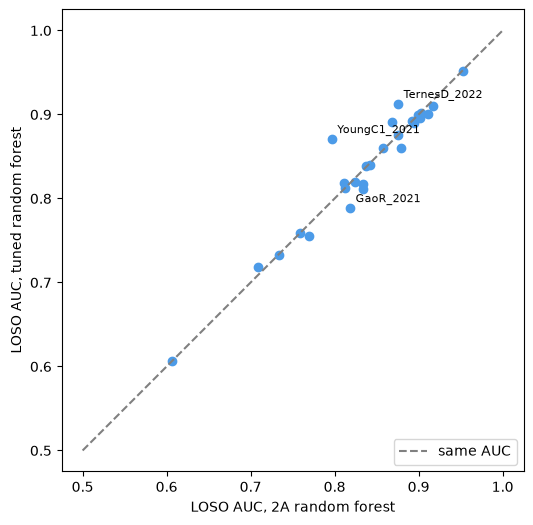

**Figure 2.** LOSO AUC per held-out study, tuned forest against the 2A forest (27 studies). Points above the line improved: 10 studies. Over the 26 studies in the paper's Table S5 the mean AUC is 0.836, against 0.836 for 2A and 0.851 in the paper. The largest change is YoungC1_2021 (+0.075).

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(loso["auc_2a"], loso["auc"], color="#4C9BE8")
ax.plot([0.5, 1], [0.5, 1], color="grey", linestyle="--", label="same AUC")
for study in difference_2a.abs().nlargest(3).index:
    ax.annotate(study, (loso.loc[study, "auc_2a"], loso.loc[study, "auc"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("LOSO AUC, 2A random forest")
ax.set_ylabel("LOSO AUC, tuned random forest")
ax.legend(loc="lower right")
ax.set_aspect("equal")

show_figure(
    fig,
    "loso_vs_2a",
    f"LOSO AUC per held-out study, tuned forest against the 2A forest ({len(loso)} studies). Points above the line "
    f"improved: {(difference_2a > 0).sum()} studies. Over the {in_paper.sum()} studies in the paper's Table S5 the mean AUC is "
    f"{loso.loc[in_paper, 'auc'].mean():.3f}, against {loso.loc[in_paper, 'auc_2a'].mean():.3f} for 2A and "
    f"{loso.loc[in_paper, 'auc_paper'].mean():.3f} in the paper. The largest change is {difference_2a.abs().idxmax()} ({difference_2a.loc[difference_2a.abs().idxmax()]:+.3f}).",
)

## 5. Which settings won

If the same settings win in almost every split, the choice is stable and easy to report. If the winner changes from split to split, the candidates score about the same and the exact choice does not matter much.

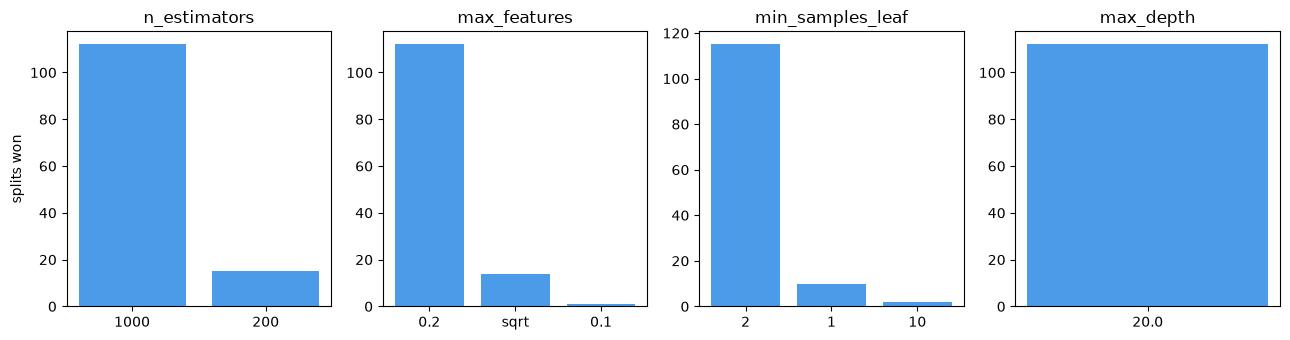

**Figure 3.** Winning value of each setting over 127 splits (100 unified, 27 LOSO). The most frequent full combination is n_estimators = 1000, max_features = 0.2, min_samples_leaf = 2, max_depth = 20.0. The inner AUC of the winners ranges from 0.785 to 0.833.

In [10]:
chosen_params = pd.DataFrame(chosen_rows).rename(columns=lambda name: name.removeprefix("model__"))
if not QUICK:
    chosen_params.to_csv(TABLES / "chosen_params.csv", index=False)

setting_names = [name.removeprefix("model__") for name in SPACE]
fig, axes = plt.subplots(1, len(setting_names), figsize=(13, 3.5))
for ax, name in zip(axes, setting_names):
    counts = chosen_params[name].astype(str).value_counts()
    ax.bar(counts.index, counts.to_numpy(), color="#4C9BE8")
    ax.set_title(name)
    ax.set_ylabel("splits won" if ax is axes[0] else "")
fig.tight_layout()

most_common = chosen_params[setting_names].astype(str).value_counts().idxmax()
show_figure(
    fig,
    "chosen_params",
    f"Winning value of each setting over {len(chosen_params)} splits ({len(chosen_params) - len(studies)} unified, {len(studies)} LOSO). "
    f"The most frequent full combination is " + ", ".join(f"{name} = {value}" for name, value in zip(setting_names, most_common))
    + f". The inner AUC of the winners ranges from {chosen_params['inner_auc'].min():.3f} to {chosen_params['inner_auc'].max():.3f}.",
)

## 6. Experiment log (MLflow)

Every full run of this notebook (`QUICK = False`) saves one MLflow record: the seed, the search space, the git commit and the final AUCs, with this notebook's tables attached. Changing a range or the search size and running again adds a new record and keeps the old one, so every hyperparameter change is documented. To browse the records, run `mlflow ui --backend-store-uri sqlite:///mlflow.db` from the project root.

In [11]:
if QUICK:
    print("QUICK mode: test run, nothing logged to MLflow")
else:
    mlflow.set_tracking_uri(f"sqlite:///{(PROJECT_ROOT / 'mlflow.db').as_posix()}")
    EXPERIMENT = "phase-2b/01_tuned_random_forest"
    if mlflow.get_experiment_by_name(EXPERIMENT) is None:
        mlflow.create_experiment(EXPERIMENT, artifact_location=(PROJECT_ROOT / "mlruns").as_uri())
    mlflow.set_experiment(EXPERIMENT)

    git_commit = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, capture_output=True, text=True).stdout.strip()
    with mlflow.start_run() as run:
        mlflow.log_params({"seed": SEED, "n_repeats": N_REPEATS, "n_iter": N_ITER,
                           "search_space": str(SPACE), "git_commit": git_commit})
        mlflow.log_metrics({"unified_auc": auc, "loso_mean_auc": loso.loc[in_paper, "auc"].mean()})
        mlflow.log_artifacts(str(TABLES))
    print(f"Logged MLflow run {run.info.run_id} in experiment {EXPERIMENT}")

2026/11/05 08:01:55 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 08:01:55 INFO mlflow.store.db.utils: Updating database tables


Logged MLflow run 3a7221b0ec8d4c6286aeb351a659a18f in experiment phase-2b/01_tuned_random_forest


## 7. Checks

In [12]:
assert not QUICK, "the reported notebook must come from the full run"
for repeat in folds:
    for train_idx, test_idx in repeat:
        assert set(groups[train_idx]).isdisjoint(groups[test_idx]), "no study on both sides of an outer split"
        assert set(y[test_idx]) == {0, 1}
        for inner_train, inner_val in StratifiedGroupKFold(n_splits=3).split(train_idx, y[train_idx], groups[train_idx]):
            assert set(groups[train_idx][inner_train]).isdisjoint(groups[train_idx][inner_val]), "no study on both sides of an inner split"
assert predictions.shape == (5966, N_REPEATS)
assert not np.isnan(predictions).any(), "every sample is tested once per repeat"
assert len(loso) == 27
assert len(chosen_params) == len(folds) * 10 + 27
assert 0.5 < auc < 1
print("All checks passed.")

All checks passed.
